In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

print("All ML libraries imported successfully!")

All ML libraries imported successfully!


In [2]:
# Load cleaned dataset

df = pd.read_csv("../dataset/student_performance_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (395, 33)


In [3]:
# Define target and features

target = "G3"

features = [
    "school",
    "sex",
    "age",
    "address",
    "famsize",
    "Pstatus",
    "Medu",
    "Fedu",
    "Mjob",
    "Fjob",
    "reason",
    "guardian",
    "traveltime",
    "studytime",
    "failures",
    "schoolsup",
    "famsup",
    "paid",
    "activities",
    "nursery",
    "higher",
    "internet",
    "romantic",
    "famrel",
    "freetime",
    "goout",
    "Dalc",
    "Walc",
    "health",
    "absences"
]

X = df[features]
y = df[target]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (395, 30)
Target: (395,)


In [4]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Numerical features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


C:\Users\Admin\AppData\Local\Temp\ipykernel_3496\1838352015.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 316
Testing records: 79


In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [7]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(
            random_state=42,
            max_depth=5
        ))
    ]
)

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            max_depth=8,
            min_samples_split=4
        ))
    ]
)

print("Three ML models created successfully!")

Three ML models created successfully!


In [8]:
print("Training Linear Regression...")
linear_model.fit(X_train, y_train)

print("Training Decision Tree...")
decision_tree_model.fit(X_train, y_train)

print("Training Random Forest...")
random_forest_model.fit(X_train, y_train)

print("\nAll models trained successfully!")

Training Linear Regression...
Training Decision Tree...
Training Random Forest...

All models trained successfully!


In [9]:
linear_predictions = linear_model.predict(X_test)

decision_tree_predictions = decision_tree_model.predict(X_test)

random_forest_predictions = random_forest_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [10]:
def evaluate_model(name, y_true, predictions):
    mae = mean_absolute_error(y_true, predictions)
    rmse = np.sqrt(mean_squared_error(y_true, predictions))
    r2 = r2_score(y_true, predictions)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    }


results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_predictions
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        decision_tree_predictions
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        random_forest_predictions
    )
)

results_df = pd.DataFrame(results)

results_df

,Model,MAE,RMSE,R²
0,Linear Regression,3.395261,4.195681,0.141492
1,Decision Tree,3.508409,4.592085,-0.028393
2,Random Forest,3.022335,3.788299,0.300113


In [16]:
# 5-Fold Cross-Validation

models = {
    "Linear Regression": linear_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="r2"
    )

    cv_results.append({
        "Model": name,
        "Mean CV R²": scores.mean(),
        "Std CV R²": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

cv_df

,Model,Mean CV R²,Std CV R²
0,Linear Regression,0.001462,0.095823
1,Decision Tree,-0.156844,0.313467
2,Random Forest,0.128870,0.127619


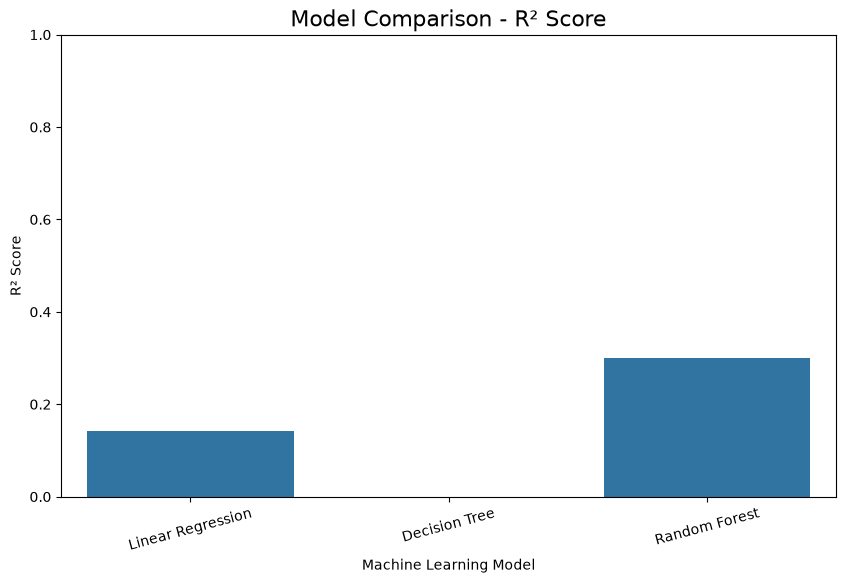

In [11]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="R²"
)

plt.title("Model Comparison - R² Score", fontsize=16)
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.show()

In [12]:
models = {
    "Linear Regression": linear_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="r2"
    )

    cv_results.append({
        "Model": name,
        "Mean CV R²": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

cv_df

,Model,Mean CV R²,Standard Deviation
0,Linear Regression,0.001462,0.095823
1,Decision Tree,-0.156844,0.313467
2,Random Forest,0.128870,0.127619


In [13]:
best_model_name = cv_df.loc[
    cv_df["Mean CV R²"].idxmax(),
    "Model"
]

print("Selected model based on mean cross-validation R²:")
print(best_model_name)

Selected model based on mean cross-validation R²:
Random Forest


In [14]:
model_mapping = {
    "Linear Regression": linear_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

best_model = model_mapping[best_model_name]

joblib.dump(
    best_model,
    "../models/student_performance_model.pkl"
)

print("Final ML pipeline saved successfully!")

Final ML pipeline saved successfully!


In [15]:
loaded_model = joblib.load(
    "../models/student_performance_model.pkl"
)

sample_prediction = loaded_model.predict(
    X_test.iloc[[0]]
)

print("Actual G3:", y_test.iloc[0])
print("Predicted G3:", round(sample_prediction[0], 2))

Actual G3: 10
Predicted G3: 9.73


In [17]:
# Select the model with the highest mean cross-validation R²

best_model_name = cv_df.loc[
    cv_df["Mean CV R²"].idxmax(),
    "Model"
]

print("Selected Model:", best_model_name)

Selected Model: Random Forest


In [18]:
# Map model names to trained pipelines

model_mapping = {
    "Linear Regression": linear_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

best_model = model_mapping[best_model_name]

# Save the complete ML pipeline
joblib.dump(
    best_model,
    "../models/student_performance_model.pkl"
)

print("Final model saved successfully!")
print("File: ../models/student_performance_model.pkl")

Final model saved successfully!
File: ../models/student_performance_model.pkl


In [19]:
# Load the final saved model

loaded_model = joblib.load(
    "../models/student_performance_model.pkl"
)

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [20]:
# Test prediction for one student

sample_student = X_test.iloc[[0]]
actual_grade = y_test.iloc[0]

predicted_grade = loaded_model.predict(sample_student)[0]

print("Actual Final Grade:", actual_grade)
print("Predicted Final Grade:", round(predicted_grade, 2))

Actual Final Grade: 10
Predicted Final Grade: 9.73


In [21]:
def performance_category(score):
    if score < 8:
        return "At Risk"
    elif score < 12:
        return "Needs Improvement"
    elif score < 16:
        return "Good"
    else:
        return "Excellent"


predicted_category = performance_category(predicted_grade)

print("Predicted Grade:", round(predicted_grade, 2))
print("Performance Category:", predicted_category)

Predicted Grade: 9.73
Performance Category: Needs Improvement


In [22]:
# Generate predictions for all test students

final_predictions = loaded_model.predict(X_test)

prediction_results = pd.DataFrame({
    "Actual Grade": y_test.values,
    "Predicted Grade": final_predictions
})

prediction_results.head(10)

,Actual Grade,Predicted Grade
0,10,9.729360
1,12,9.262906
2,5,10.156832
3,10,12.022593
4,9,10.050313
5,13,9.649825
6,18,13.512684
7,6,11.326716
8,0,10.313154
9,14,12.028376


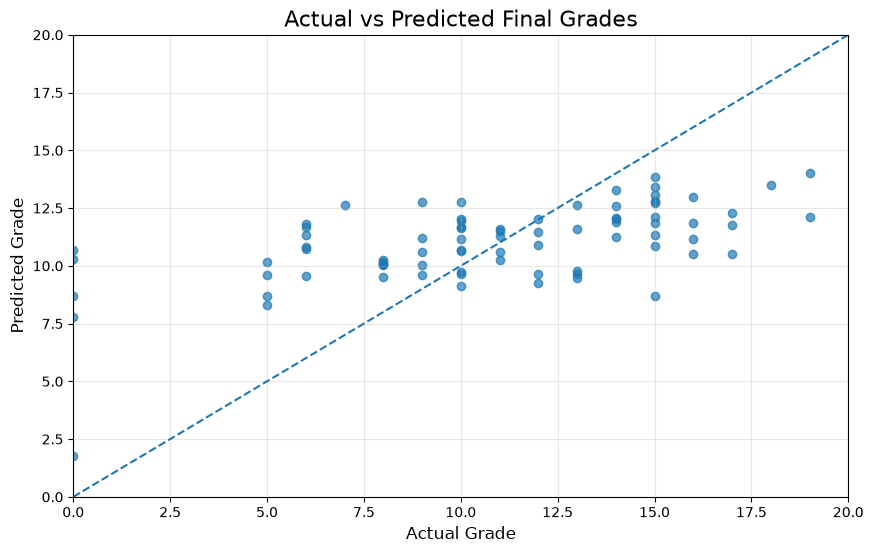

In [23]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.7
)

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--"
)

plt.title("Actual vs Predicted Final Grades", fontsize=16)
plt.xlabel("Actual Grade", fontsize=12)
plt.ylabel("Predicted Grade", fontsize=12)
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.grid(alpha=0.3)

plt.show()

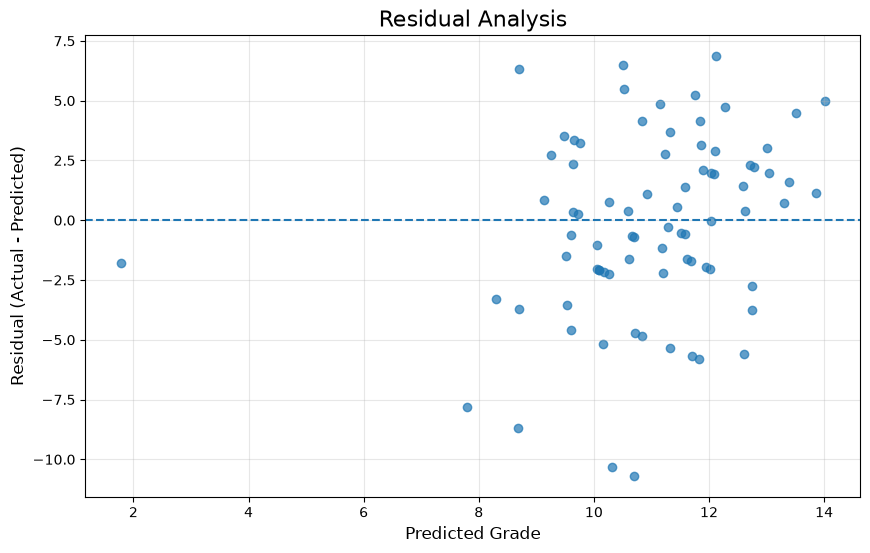

In [24]:
# Calculate prediction residuals

residuals = y_test.values - final_predictions

plt.figure(figsize=(10, 6))

plt.scatter(
    final_predictions,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residual Analysis", fontsize=16)
plt.xlabel("Predicted Grade", fontsize=12)
plt.ylabel("Residual (Actual - Predicted)", fontsize=12)
plt.grid(alpha=0.3)

plt.show()

In [25]:
# Feature importance from Random Forest

rf_model = loaded_model.named_steps["model"]
preprocessor_fitted = loaded_model.named_steps["preprocessor"]

feature_names = preprocessor_fitted.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
55,numerical__absences,0.209971
48,numerical__failures,0.172347
54,numerical__health,0.047453
51,numerical__goout,0.044609
43,numerical__age,0.037332
47,numerical__studytime,0.030110
46,numerical__traveltime,0.028770
50,numerical__freetime,0.027782
45,numerical__Fedu,0.022900
49,numerical__famrel,0.022298


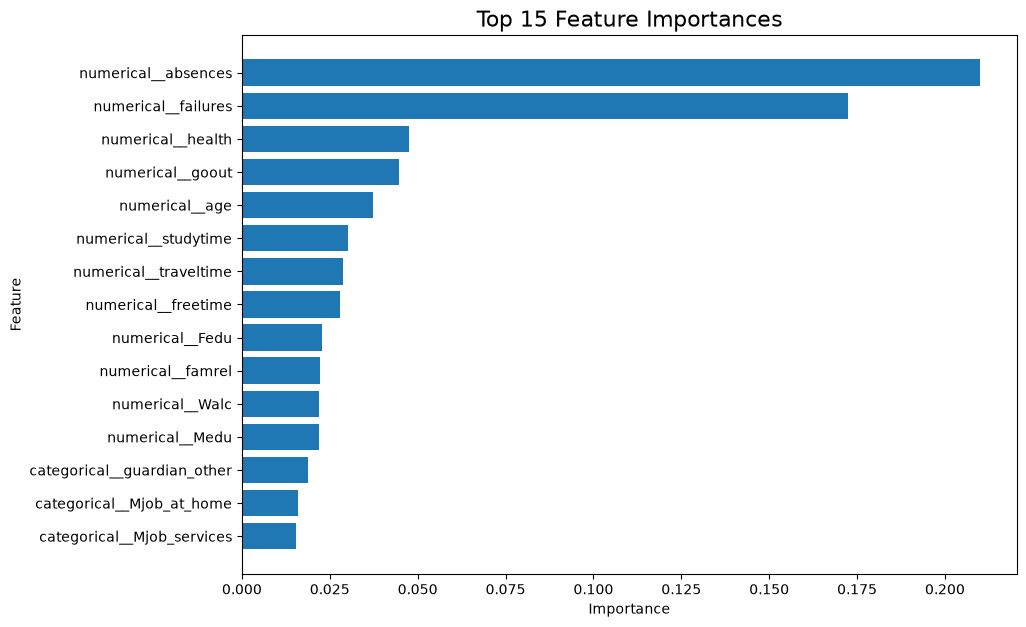

In [26]:
# Top 15 feature importances

top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Feature Importances", fontsize=16)
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [27]:
# Save model evaluation results

results_df.to_csv(
    "../models/model_comparison.csv",
    index=False
)

cv_df.to_csv(
    "../models/cross_validation_results.csv",
    index=False
)

print("Model evaluation results saved successfully!")

Model evaluation results saved successfully!


In [28]:
# Save test predictions

prediction_results.to_csv(
    "../models/test_predictions.csv",
    index=False
)

print("Test predictions saved successfully!")

Test predictions saved successfully!


In [29]:
# Final ML evaluation report

best_row = results_df.loc[
    results_df["Model"] == best_model_name
].iloc[0]

best_cv_row = cv_df.loc[
    cv_df["Model"] == best_model_name
].iloc[0]

print("=" * 55)
print("STUDENT PERFORMANCE PREDICTION - ML REPORT")
print("=" * 55)

print(f"\nSelected Model: {best_model_name}")

print("\nTest Set Performance:")
print(f"MAE  : {best_row['MAE']:.3f}")
print(f"RMSE : {best_row['RMSE']:.3f}")
print(f"R²   : {best_row['R²']:.3f}")

print("\n5-Fold Cross-Validation:")
print(f"Mean CV R² : {best_cv_row['Mean CV R²']:.3f}")
print(f"Std CV R²  : {best_cv_row['Std CV R²']:.3f}")

print("\nTraining records:", len(X_train))
print("Testing records :", len(X_test))

print("\nTarget variable: G3")
print("Maximum grade  : 20")

print("\nModel pipeline saved successfully.")
print("=" * 55)

STUDENT PERFORMANCE PREDICTION - ML REPORT

Selected Model: Random Forest

Test Set Performance:
MAE  : 3.022
RMSE : 3.788
R²   : 0.300

5-Fold Cross-Validation:
Mean CV R² : 0.129
Std CV R²  : 0.128

Training records: 316
Testing records : 79

Target variable: G3
Maximum grade  : 20

Model pipeline saved successfully.
